# AN8 Part 3 — Semantic Analysis and Controlled Transformations

**Status:** P3.00/P3.07 passed structural gates. P3.01/P3.03/P3.04/P3.06 are accepted retained diagnostics and are not repeated for confirmation. P3.02/P3.05 retained outputs remain historical because their SQL was revised. Their previously accepted evidence is reused; P3.09 now supplies the richer assessment-level sentinel, timing, and opportunity analysis, so a separate P3.05 fifth-result rerun is not required unless P3.09 fails reconciliation.

**Purpose:** Interpret source-semantic diagnostics, display retained evidence and visualizations, record decisions, and define controlled derived representations. No source-data changes or persistent database objects are created here.

## Operating boundaries

- Notebook 10 remains the AN8 Part 2 evidence record.
- Canonical SQL remains under `sql/05_part3`; this notebook invokes the guarded runner.
- CSV exports are checked against manifest hashes, row counts, and the current SQL file hash.
- A manifest from an older SQL version is historical, not current evidence.
- Never load all of `student_vle` into one Pandas DataFrame.
- Original files and PostgreSQL RAW, QUALITY, and STAGING remain immutable.
- No deduplication, imputation, clipping, sentinel recoding, or persistent derived object is approved by these diagnostics.
- No prediction, ML training, or Power BI work is performed here.

## 00 — Environment and project paths

The first code cell locates the repository root and imports the libraries needed for the workflow. Database access is deliberately deferred to the guarded setup and execution cells below.

In [1]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import pandas as pd

def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    candidates = [current, *current.parents]
    for candidate in candidates:
        if (candidate / "sql" / "05_part3").is_dir() and (candidate / ".git").exists():
            return candidate
    raise FileNotFoundError("Could not locate the OULAD project root from the notebook directory.")

PROJECT_ROOT = find_project_root()
PART3_OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "an8" / "part3"

print(f"Project root: {PROJECT_ROOT}")
print(f"Part 3 output root: {PART3_OUTPUT_ROOT}")
print(f"Part 3 output directory exists: {PART3_OUTPUT_ROOT.is_dir()}")

Project root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics
Part 3 output root: G:\OULAD-EdTech-Learning-Analytics-starter\OULAD-EdTech-Learning-Analytics\outputs\an8\part3
Part 3 output directory exists: True


## 01 — Guarded database and schema setup

This section is the notebook's auditable bootstrap record. It creates `oulad_an8_work` only when the database is absent. It creates the four schemas and seven source-faithful TEXT tables only when none of those objects exists. If the database or objects already exist, it verifies them and skips creation. A partial or unexpected state stops for inspection; nothing is dropped or overwritten.

The original `oulad_analytics` database and its RAW, QUALITY, and STAGING layers are never targeted.

In [2]:
import os
import subprocess
import sys

import psycopg
from psycopg import sql
from dotenv import load_dotenv

load_dotenv(PROJECT_ROOT / ".env", override=False)

DB_CONFIG = {
    "host": os.getenv("DB_HOST", "localhost"),
    "port": os.getenv("DB_PORT", "5432"),
    "user": os.getenv("DB_USER", "postgres"),
    "password": os.getenv("DB_PASSWORD"),
}
WORK_DATABASE = "oulad_an8_work"

if not DB_CONFIG["password"] or DB_CONFIG["password"] == "CHANGE_ME":
    raise RuntimeError("DB_PASSWORD is missing or invalid in the project .env file.")

EXPECTED_SCHEMAS = {"source_ref", "working", "audit", "derived"}
EXPECTED_TABLES = {
    "courses", "assessments", "student_info", "student_registration",
    "student_assessment", "vle", "student_vle",
}

# 1. Create the isolated database only if it does not already exist.
with psycopg.connect(**DB_CONFIG, dbname="postgres", autocommit=True) as conn:
    with conn.cursor() as cur:
        cur.execute(
            "SELECT EXISTS (SELECT 1 FROM pg_database WHERE datname = %s)",
            (WORK_DATABASE,),
        )
        database_exists = cur.fetchone()[0]

        if database_exists:
            print(f"Database already exists; creation skipped: {WORK_DATABASE}")
        else:
            create_sql_path = PROJECT_ROOT / "sql" / "00_database" / "02_create_oulad_an8_work.sql"
            cur.execute(create_sql_path.read_text(encoding="utf-8"), prepare=False)
            print(f"Database created: {WORK_DATABASE}")

# 2. Create schemas/tables only in a completely empty setup state.
with psycopg.connect(**DB_CONFIG, dbname=WORK_DATABASE, autocommit=True) as conn:
    with conn.cursor() as cur:
        cur.execute(
            "SELECT schema_name FROM information_schema.schemata "
            "WHERE schema_name = ANY(%s)",
            (list(EXPECTED_SCHEMAS),),
        )
        existing_schemas = {row[0] for row in cur.fetchall()}

        cur.execute(
            "SELECT table_name FROM information_schema.tables "
            "WHERE table_schema = 'source_ref' AND table_type = 'BASE TABLE'"
        )
        existing_tables = {row[0] for row in cur.fetchall()}

        if not existing_schemas and not existing_tables:
            ddl_path = PROJECT_ROOT / "sql" / "05_part3" / "00_create_source_ref_tables.sql"
            cur.execute(ddl_path.read_text(encoding="utf-8"), prepare=False)
            print("Created four schemas and seven source_ref tables.")
        elif existing_schemas == EXPECTED_SCHEMAS and existing_tables == EXPECTED_TABLES:
            print("Expected schemas and source tables already exist; DDL skipped.")
        else:
            raise RuntimeError(
                "Partial/unexpected setup detected. No DDL was rerun. "
                f"Schemas found={sorted(existing_schemas)}; "
                f"source_ref tables found={sorted(existing_tables)}. "
                "Inspect this state before proceeding."
            )

        # 3. Verify exact schema/table inventory and TEXT column types.
        cur.execute(
            "SELECT schema_name FROM information_schema.schemata "
            "WHERE schema_name = ANY(%s)",
            (list(EXPECTED_SCHEMAS),),
        )
        verified_schemas = {row[0] for row in cur.fetchall()}
        if verified_schemas != EXPECTED_SCHEMAS:
            raise RuntimeError(f"Schema verification failed: {sorted(verified_schemas)}")

        cur.execute(
            "SELECT table_name FROM information_schema.tables "
            "WHERE table_schema = 'source_ref' AND table_type = 'BASE TABLE'"
        )
        verified_tables = {row[0] for row in cur.fetchall()}
        if verified_tables != EXPECTED_TABLES:
            raise RuntimeError(f"Table verification failed: {sorted(verified_tables)}")

        cur.execute(
            "SELECT table_name, column_name, data_type "
            "FROM information_schema.columns WHERE table_schema = 'source_ref'"
        )
        column_rows = cur.fetchall()
        if not column_rows or any(row[2].lower() != "text" for row in column_rows):
            raise RuntimeError("Source table columns are missing or not all TEXT.")

print("SETUP VERIFICATION: PASS")
print("Schemas:", sorted(verified_schemas))
print("Source tables:", sorted(verified_tables))
print(f"Verified TEXT columns: {len(column_rows)}")

Database already exists; creation skipped: oulad_an8_work
Expected schemas and source tables already exist; DDL skipped.
SETUP VERIFICATION: PASS
Schemas: ['audit', 'derived', 'source_ref', 'working']
Source tables: ['assessments', 'courses', 'student_assessment', 'student_info', 'student_registration', 'student_vle', 'vle']
Verified TEXT columns: 43


## 01A — Historical setup and import evidence (owner-returned)

The following evidence was transcribed from the owner's PowerShell output on 2026-11-26 at approximately 17:58 UTC. It records work completed before this notebook orchestration was added. The table below is a documentation record of the returned console output, not a claim that this notebook executed the setup/import cells. The guarded cells above/below independently verify existing state when run.

The reported database creation, four-schema verification, seven-table empty-state verification, SHA-256/header validation, and transactional import all completed successfully. The importer reported `IMPORT COMMITTED` and stated that no source files or other databases were modified.

In [3]:
HISTORICAL_IMPORT_EVIDENCE = [
    {"source_file": "courses.csv", "sha256": "4F16EEE7454B15E109B0A21A0E43BE820E6846ED6F9301BB7FEB5AB5AD737A75", "imported_rows": 22},
    {"source_file": "assessments.csv", "sha256": "9CE92381E4A0AC457F8E251B2EB2C179ED51E023AB30D1D671A0268BD62316BA", "imported_rows": 206},
    {"source_file": "studentInfo.csv", "sha256": "815FBC3E2DE29F79900BC63F0345A35DB62C9146AFAA1D86E7107B8B3BEFFC60", "imported_rows": 32593},
    {"source_file": "studentRegistration.csv", "sha256": "BBC87A0DE1FE2A9EC6DECCE1CA6C1A02CF17B54AD3BDCC673FC6413B41C61D47", "imported_rows": 32593},
    {"source_file": "studentAssessment.csv", "sha256": "B1839E17618A5DE36B6D189A242D3123F7939A56C8C9CCEF0C17B9199C614A6B", "imported_rows": 173912},
    {"source_file": "vle.csv", "sha256": "D7A146497EDD0E47EF536144B58796C07B554002D3753E848B8E4CD8A56F4C38", "imported_rows": 6364},
    {"source_file": "studentVle.csv", "sha256": "52668253D876C5BECBCB72185977152700CECAB2942ACA807FECC3DD54B937F0", "imported_rows": 10655280},
]

historical_import_frame = pd.DataFrame(HISTORICAL_IMPORT_EVIDENCE)
display(historical_import_frame)
print("Reported target database: oulad_an8_work")
print("Reported schemas: audit, derived, source_ref, working")
print("Reported source_ref tables: 7/7; initially empty before import")
print("Reported import result: IMPORT COMMITTED")
print("Evidence provenance: owner-returned PowerShell output, 2026-11-26")
print("This is a transcribed evidence record, not notebook execution evidence.")

,source_file,sha256,imported_rows
0,courses.csv,4F16EEE7454B15E109B0A21A0E43BE820E6846ED6F9301...,22
1,assessments.csv,9CE92381E4A0AC457F8E251B2EB2C179ED51E023AB30D1...,206
2,studentInfo.csv,815FBC3E2DE29F79900BC63F0345A35DB62C9146AFAA1D...,32593
3,studentRegistration.csv,BBC87A0DE1FE2A9EC6DECCE1CA6C1A02CF17B54AD3BDCC...,32593
4,studentAssessment.csv,B1839E17618A5DE36B6D189A242D3123F7939A56C8C9CC...,173912
5,vle.csv,D7A146497EDD0E47EF536144B58796C07B554002D3753E...,6364
6,studentVle.csv,52668253D876C5BECBCB72185977152700CECAB2942ACA...,10655280


Reported target database: oulad_an8_work
Reported schemas: audit, derived, source_ref, working
Reported source_ref tables: 7/7; initially empty before import
Reported import result: IMPORT COMMITTED
Evidence provenance: owner-returned PowerShell output, 2026-11-26
This is a transcribed evidence record, not notebook execution evidence.


## 02 — Guarded seven-file source import

The importer validates the working CSV hashes and headers against the backup manifest, then loads all seven files in one transaction. This notebook cell checks database row counts first:

- If all seven tables are empty, it invokes the existing controlled importer.
- If all seven tables already have their expected row counts, it skips import.
- If the database is partially populated or counts differ, it stops rather than attempting a second import.

The importer is launched by the notebook kernel and its console output is captured in this cell's saved output. No PowerShell/Python terminal command is required.

In [4]:
EXPECTED_SOURCE_ROWS = {
    "courses": 22,
    "assessments": 206,
    "student_info": 32593,
    "student_registration": 32593,
    "student_assessment": 173912,
    "vle": 6364,
    "student_vle": 10655280,
}

def get_source_row_counts():
    counts = {}
    with psycopg.connect(**DB_CONFIG, dbname=WORK_DATABASE) as conn:
        with conn.cursor() as cur:
            for table in sorted(EXPECTED_SOURCE_ROWS):
                cur.execute(
                    sql.SQL("SELECT COUNT(*) FROM source_ref.{}").format(
                        sql.Identifier(table)
                    )
                )
                counts[table] = cur.fetchone()[0]
    return counts

current_counts = get_source_row_counts()

if current_counts == EXPECTED_SOURCE_ROWS:
    print("SOURCE IMPORT SKIPPED: all seven tables already contain the expected row counts.")
    print("The existing committed import will be reconciled by P3.00.")
elif all(count == 0 for count in current_counts.values()):
    importer_path = PROJECT_ROOT / "scripts" / "import_part3_source.py"
    completed = subprocess.run(
        [sys.executable, str(importer_path)],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        check=False,
    )
    print(completed.stdout)
    if completed.stderr:
        print("STDERR:")
        print(completed.stderr)
    if completed.returncode != 0:
        raise RuntimeError(
            f"Controlled source import failed with exit code {completed.returncode}."
        )
    current_counts = get_source_row_counts()
    if current_counts != EXPECTED_SOURCE_ROWS:
        raise RuntimeError(
            f"Post-import row-count verification failed: {current_counts}"
        )
    print("SOURCE IMPORT AND ROW-COUNT VERIFICATION: PASS")
else:
    raise RuntimeError(
        "Partial source import detected. Import was NOT repeated. "
        f"Current counts: {current_counts}"
    )

display(pd.Series(current_counts, name="rows").to_frame())
print("Import state verified; no source files or original database were modified.")

SOURCE IMPORT SKIPPED: all seven tables already contain the expected row counts.
The existing committed import will be reconciled by P3.00.


,rows
assessments,206
courses,22
student_assessment,173912
student_info,32593
student_registration,32593
student_vle,10655280
vle,6364


Import state verified; no source files or original database were modified.


## 03 — Load and verify one query execution

The notebook invokes scripts/run_part3.py for exactly one query at a time. Each run creates a timestamped folder containing result_set_XX.csv files and execution_manifest.json. The helper below verifies the exported file hashes before loading them. Use it only for result sets small enough to fit in memory; P3.04 and other larger outputs may require chunked CSV reading.

In [5]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest().upper()

def find_query_manifests(query_id: str) -> list[Path]:
    return sorted(PART3_OUTPUT_ROOT.glob(f"*/{query_id}/execution_manifest.json"),
                  key=lambda p: p.parent.parent.name)

def load_query_results(query_id: str, run_directory: Path | None = None, *, allow_stale: bool = False):
    manifests = find_query_manifests(query_id)
    manifest_path = (Path(run_directory) / "execution_manifest.json") if run_directory else manifests[-1]
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("query_id") != query_id or manifest.get("read_only") is not True:
        raise ValueError("Unexpected query identity or read-only status.")
    query_path = PROJECT_ROOT / manifest["query_file"]
    current_sha = sha256_file(query_path)
    stale = manifest.get("query_sha256") != current_sha
    if stale and not allow_stale:
        raise ValueError(f"{query_id} manifest is stale; canonical SQL hash changed.")
    frames = {}
    for item in manifest["result_sets"]:
        csv_path = manifest_path.parent / item["file"]
        if sha256_file(csv_path) != item["sha256"]:
            raise ValueError(f"Export hash mismatch: {csv_path}")
        frame = pd.read_csv(csv_path, low_memory=False)
        if len(frame) != item["rows"]:
            raise ValueError(f"Export row-count mismatch: {csv_path}")
        frames[item["result_set"]] = frame
    manifest["_sql_is_stale"] = stale
    manifest["_current_query_sha256"] = current_sha
    return manifest, frames

def load_or_execute_part3_query(query_id: str, authorize: bool = False):
    sql_files = list((PROJECT_ROOT / "sql" / "05_part3").glob(f"{query_id}_*.sql"))
    if len(sql_files) != 1:
        raise FileNotFoundError(f"Expected one canonical SQL file for {query_id}.")
    current_sha = sha256_file(sql_files[0])
    manifests = find_query_manifests(query_id)
    for manifest_path in reversed(manifests):
        saved = json.loads(manifest_path.read_text(encoding="utf-8"))
        if saved.get("query_sha256") == current_sha:
            manifest, frames = load_query_results(query_id, manifest_path.parent)
            print(f"{query_id}: current retained execution loaded.")
            return manifest, frames
    if authorize:
        return execute_part3_query(query_id)
    print(f"{query_id}: no current-hash manifest; retained outputs are historical.")
    return None, None

print("Available P3.00 manifests:", len(find_query_manifests("P3.00")))
print("Available P3.07 manifests:", len(find_query_manifests("P3.07")))

Available P3.00 manifests: 1
Available P3.07 manifests: 1


### Notebook-controlled SQL execution gates

The following cells invoke the existing one-query runner from the notebook kernel. The runner connects only to `oulad_an8_work`, enforces a read-only transaction, and stores complete CSV exports plus a manifest. The captured stdout becomes part of the notebook execution record. Both query-authorization switches default to `False`; set the relevant switch to `True` only when you are ready to execute that query, then run that cell individually. P3.07 remains blocked until the P3.00 validation cell passes.

In [6]:
def execute_part3_query(query_id: str):
    runner_path = PROJECT_ROOT / "scripts" / "run_part3.py"
    completed = subprocess.run(
        [
            sys.executable, str(runner_path),
            "--query", query_id,
            "--statement-timeout-ms", "0",
        ],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
        check=False,
    )
    print(completed.stdout)
    if completed.stderr:
        print("STDERR:")
        print(completed.stderr)
    if completed.returncode != 0:
        raise RuntimeError(
            f"{query_id} failed with exit code {completed.returncode}."
        )
    return load_query_results(query_id)


# Use the single hash-aware loader defined in Section 01.
# A retained export is reusable only when its SQL hash matches the current query.
AUTHORIZE_P300_EXECUTION = False
p300_manifest, p300_results = load_or_execute_part3_query(
    "P3.00", AUTHORIZE_P300_EXECUTION
)

P3.00: existing retained execution loaded; no SQL rerun.


In [7]:
EXPECTED_SOURCE_COLUMNS = {
    "courses": {"code_module", "code_presentation", "module_presentation_length"},
    "assessments": {"code_module", "code_presentation", "id_assessment", "assessment_type", "date", "weight"},
    "student_info": {"code_module", "code_presentation", "id_student", "gender", "region", "highest_education", "imd_band", "age_band", "num_of_prev_attempts", "studied_credits", "disability", "final_result"},
    "student_registration": {"id_student", "code_module", "code_presentation", "date_registration", "date_unregistration"},
    "student_assessment": {"id_assessment", "id_student", "date_submitted", "is_banked", "score"},
    "vle": {"id_site", "code_module", "code_presentation", "activity_type", "week_from", "week_to"},
    "student_vle": {"code_module", "code_presentation", "id_student", "id_site", "date", "sum_click"},
}

P300_GATE_PASSED = False

if p300_manifest is None or p300_results is None:
    print("P3.00 VALIDATION NOT RUN — the P3.00 execution cell is still gated.")
else:
    if p300_manifest["database"]["database"] != WORK_DATABASE:
        raise RuntimeError("P3.00 ran against an unexpected database.")
    if p300_manifest.get("read_only") is not True:
        raise RuntimeError("P3.00 was not executed read-only.")
    if len(p300_results) != 3:
        raise RuntimeError(f"P3.00 expected 3 result sets; found {len(p300_results)}.")

    # Result set 1: exact column names and TEXT types.
    column_frame = p300_results[1]
    actual_columns = {}
    for row in column_frame.itertuples(index=False):
        actual_columns.setdefault(row.table_name, set()).add(row.column_name)
        if str(row.data_type).lower() != "text":
            raise RuntimeError(
                f"Non-TEXT column found: {row.table_name}.{row.column_name}={row.data_type}"
            )
    if actual_columns != EXPECTED_SOURCE_COLUMNS:
        raise RuntimeError(
            f"Column inventory mismatch. Actual: {actual_columns}"
        )

    # Result set 2: exact row-count reconciliation.
    count_frame = p300_results[2]
    actual_counts = dict(zip(count_frame["source_table"], count_frame["exact_rows"].astype(int)))
    if actual_counts != EXPECTED_SOURCE_ROWS:
        raise RuntimeError(
            f"Source row-count mismatch. Expected={EXPECTED_SOURCE_ROWS}; actual={actual_counts}"
        )

    # Result set 3: exact source relation inventory.
    relation_frame = p300_results[3]
    actual_relations = set(relation_frame["table_name"])
    if actual_relations != set(EXPECTED_SOURCE_ROWS):
        raise RuntimeError(f"Unexpected source relation inventory: {sorted(actual_relations)}")

    P300_GATE_PASSED = True
    print("P3.00 VALIDATION: PASS")
    print("Seven table schemas match; all source columns are TEXT.")
    display(count_frame.sort_values("source_table").reset_index(drop=True))
    print("P3.07 is permitted to run.")

P3.00 VALIDATION: PASS
Seven table schemas match; all source columns are TEXT.


,source_table,exact_rows
0,assessments,206
1,courses,22
2,student_assessment,173912
3,student_info,32593
4,student_registration,32593
5,student_vle,10655280
6,vle,6364


P3.07 is permitted to run.


In [8]:
# P3.07 is a high-cost scan. Reuse its retained evidence before considering execution.
AUTHORIZE_P307_EXECUTION = False

if not globals().get("P300_GATE_PASSED", False):
    print("P3.07 BLOCKED — P3.00 validation has not passed.")
else:
    p307_manifest, p307_results = load_or_execute_part3_query(
        "P3.07", AUTHORIZE_P307_EXECUTION
    )
    if p307_manifest is not None:
        print("P3.07 evidence is available for review in Section 05.")

P3.07: existing retained execution loaded; no SQL rerun.
P3.07 evidence is available for review in Section 05.


## 04 — P3.00 source-import reconciliation

P3.00 is executed from the notebook-controlled gate above. This section displays its retained results and execution metadata. Compare the exact imported row counts with the approved source inventory: courses 22, assessments 206, student_info 32,593, student_registration 32,593, student_assessment 173,912, vle 6,364, and student_vle 10,655,280. Any mismatch blocks further analysis.

In [9]:
EXPECTED_SOURCE_ROWS = {
    "courses": 22,
    "assessments": 206,
    "student_info": 32593,
    "student_registration": 32593,
    "student_assessment": 173912,
    "vle": 6364,
    "student_vle": 10655280,
}

p300_manifest = None
p300_results = None

if find_query_manifests("P3.00"):
    p300_manifest, p300_results = load_query_results("P3.00")
    print("Execution metadata:")
    display(pd.Series({
        "executed_at_utc": p300_manifest["executed_at_utc"],
        "elapsed_seconds": p300_manifest["elapsed_seconds"],
        "database": p300_manifest["database"]["database"],
        "read_only": p300_manifest["read_only"],
    }).to_frame("value"))

    for result_number, frame in p300_results.items():
        print(f"P3.00 result set {result_number}")
        display(frame)
else:
    print("P3.00 NOT AVAILABLE — no SQL execution is inferred.")

Execution metadata:


,value
executed_at_utc,2026-11-26T19:07:19.432650+00:00
elapsed_seconds,2.884
database,oulad_an8_work
read_only,True


P3.00 result set 1


,table_name,ordinal_position,column_name,data_type,is_nullable
0,assessments,1,code_module,text,YES
1,assessments,2,code_presentation,text,YES
2,assessments,3,id_assessment,text,YES
3,assessments,4,assessment_type,text,YES
4,assessments,5,date,text,YES
5,assessments,6,weight,text,YES
6,courses,1,code_module,text,YES
7,courses,2,code_presentation,text,YES
8,courses,3,module_presentation_length,text,YES
9,student_assessment,1,id_assessment,text,YES


P3.00 result set 2


,source_table,exact_rows
0,assessments,206
1,courses,22
2,student_assessment,173912
3,student_info,32593
4,student_registration,32593
5,student_vle,10655280
6,vle,6364


P3.00 result set 3


,table_name
0,assessments
1,courses
2,student_assessment
3,student_info
4,student_registration
5,student_vle
6,vle


## 05 — P3.07 grain and join gate

P3.07 is executed from the notebook only after P3.00 passes. Review it before interpreting any cross-domain join. Inspect duplicate-key counts, registration/profile key-set differences, join row counts, and the activity reference-match matrix. A duplicate count is evidence of a key issue, not permission to delete records.

In [10]:
p307_manifest = None
p307_results = None

if find_query_manifests("P3.07"):
    p307_manifest, p307_results = load_query_results("P3.07")
    print("Execution metadata:")
    display(pd.Series({
        "executed_at_utc": p307_manifest["executed_at_utc"],
        "elapsed_seconds": p307_manifest["elapsed_seconds"],
        "database": p307_manifest["database"]["database"],
        "read_only": p307_manifest["read_only"],
    }).to_frame("value"))

    for result_number, frame in p307_results.items():
        print(f"P3.07 result set {result_number}")
        display(frame)
else:
    print("P3.07 NOT AVAILABLE — the cross-domain gate remains unreviewed.")

Execution metadata:


,value
executed_at_utc,2026-11-26T19:10:19.759571+00:00
elapsed_seconds,59.346
database,oulad_an8_work
read_only,True


P3.07 result set 1


,key_name,duplicate_groups
0,assessments(id_assessment),0
1,"courses(module,presentation)",0
2,"student_assessment(assessment,student)",0
3,"student_info(module,presentation,student)",0
4,"student_registration(module,presentation,student)",0
5,"vle(module,presentation,site)",0


P3.07 result set 2


,join_stage,rows,unmatched_keys,multiple_match_keys
0,after_course_lookup,32593,0,0
1,after_profile_lookup,32593,0,0
2,key_set_difference:profile_without_registration,0,0,0
3,key_set_difference:registration_without_profile,0,0,0
4,registration_base,32593,0,0


P3.07 result set 3


,course_match_state,registration_match_state,profile_match_state,resource_match_state,source_activity_rows
0,ONE_COURSE_MATCH,ONE_REGISTRATION_MATCH,ONE_PROFILE_MATCH,ONE_RESOURCE_MATCH,10655280


## 06 — P3.00 and P3.07 reviewed findings

### P3.00 — source-import reconciliation: PASS

- Executed at **2026-11-26 19:07:19 UTC** against `oulad_an8_work`, read-only; elapsed 2.884 seconds.
- Seven source relations had the exact expected column names and order: 43 columns total, all TEXT.
- Exact row counts reconciled: courses 22; assessments 206; student_info 32,593; student_registration 32,593; student_assessment 173,912; vle 6,364; student_vle 10,655,280.
- Exactly the seven expected source relations were present.

**Interpretation:** the isolated source snapshot passed structural and row-count reconciliation. This is not a semantic quality verdict. TEXT is intentional in the immutable source-reference layer; typed and cleaned fields belong in later working representations.

### P3.07 — tested grain and join-cardinality gate: PASS

- Executed at **2026-11-26 19:10:19 UTC** against `oulad_an8_work`, read-only; elapsed 59.346 seconds.
- Six tested candidate keys had zero duplicate groups: courses (module/presentation), assessments (assessment ID), student_info (module/presentation/student), student_registration (module/presentation/student), student_assessment (assessment/student), and vle (module/presentation/site).
- The registered cohort contained 32,593 rows before and after course/profile lookups. There were zero unmatched keys, zero multiple matches, and zero one-sided profile/registration key-set differences.
- All 10,655,280 student_vle rows matched exactly one course, one registration, one profile, and one VLE resource in the tested reference pattern.

**Interpretation:** the tested metadata-aware joins do not introduce fan-out. Use the composite student-presentation key for cohort joins. This does **not** resolve the repeated five-key student_vle event pattern; P3.01 must inspect original rows.

### Decisions

1. Accept the seven imported source tables as the reconciled Part 3 input snapshot.
2. Permit planned diagnostic joins using the tested composite keys; validate every new join path at its own grain.
3. Do not delete, aggregate, or replace student_vle rows yet. P3.07 tested lookup cardinality, not event semantics.
4. Do not treat negative relative days as invalid; P3.02 must quantify and classify them against presentation length.
5. Keep `date_submitted = -1`, missing registration dates, zero activity, NULL scores, and observed zero scores as separate states pending linked evidence.

**Evidence boundary:** the findings above are based on the saved notebook outputs. Execution manifests and CSV exports remain in the local ignored output directory; they are not committed as repository data.

## 07 — Read-only diagnostic execution gates

P3.00/P3.07 passed. P3.01/P3.03/P3.04/P3.06 retained outputs are accepted. The previously retained P3.02 temporal distribution is used as historical baseline; its revised stratified boundary sample is not required for the assessment opportunity work unless a specific boundary question remains. P3.05's retained four-result output is also historical, but P3.09 now provides the richer -1 case list, source-row total, negative-day breakdown, and per-assessment opportunity reconciliation. Do not rerun P3.05 solely for its fifth result set.

All query authorization switches default to `False`. The runner reuses only outputs whose manifest SQL hash matches the current query. Do not use Run All. Execute P3.09 individually after loading the existing P3.00/P3.07 evidence gates.

In [11]:
# P3.01 — original rows in conflicting repeated student_vle groups
AUTHORIZE_P301_EXECUTION = False
p301_manifest, p301_results = (None, None)
if not P300_GATE_PASSED or p307_manifest is None:
    print("P3.01 BLOCKED — P3.00/P3.07 structural gates are unavailable.")
else:
    p301_manifest, p301_results = load_or_execute_part3_query("P3.01", AUTHORIZE_P301_EXECUTION)

Query: P3.01
Database: oulad_an8_work
Read-only: on
Elapsed seconds: 251.628
Result set 1: 430 rows -> result_set_01.csv
Manifest: outputs\an8\part3\20261126T201253Z\P3.01\execution_manifest.json
READ-ONLY EXECUTION COMPLETED. No source or database data was modified.



In [ ]:
# P3.02 — relative-day distributions and temporal boundary samples
AUTHORIZE_P302_EXECUTION = False
p302_manifest, p302_results = (None, None)
if not P300_GATE_PASSED or p307_manifest is None:
    print("P3.02 BLOCKED — P3.00/P3.07 structural gates are unavailable.")
else:
    p302_manifest, p302_results = load_or_execute_part3_query("P3.02", AUTHORIZE_P302_EXECUTION)

Query: P3.02
Database: oulad_an8_work
Read-only: on
Elapsed seconds: 130.256
Result set 1: 5 rows -> result_set_01.csv
Result set 2: 200 rows -> result_set_02.csv
Result set 3: 22 rows -> result_set_03.csv
Manifest: outputs\an8\part3\20261126T203012Z\P3.02\execution_manifest.json
READ-ONLY EXECUTION COMPLETED. No source or database data was modified.



In [ ]:
# P3.05 — submission sentinel, score, banked, and missing due-date context
AUTHORIZE_P305_EXECUTION = False
p305_manifest, p305_results = (None, None)
if not P300_GATE_PASSED or p307_manifest is None:
    print("P3.05 BLOCKED — P3.00/P3.07 structural gates are unavailable.")
else:
    p305_manifest, p305_results = load_or_execute_part3_query("P3.05", AUTHORIZE_P305_EXECUTION)

Query: P3.05
Database: oulad_an8_work
Read-only: on
Elapsed seconds: 2.782
Result set 1: 1,927 rows -> result_set_01.csv
Result set 2: 18 rows -> result_set_02.csv
Result set 3: 0 rows -> result_set_03.csv
Result set 4: 11 rows -> result_set_04.csv
Manifest: outputs\an8\part3\20261126T203318Z\P3.05\execution_manifest.json
READ-ONLY EXECUTION COMPLETED. No source or database data was modified.



In [20]:
# P3.03 — registration missingness and exposure context
AUTHORIZE_P303_EXECUTION = False
p303_manifest, p303_results = (None, None)
if not P300_GATE_PASSED or p307_manifest is None:
    print("P3.03 BLOCKED — P3.00/P3.07 structural gates are unavailable.")
else:
    p303_manifest, p303_results = load_or_execute_part3_query("P3.03", AUTHORIZE_P303_EXECUTION)

Query: P3.03
Database: oulad_an8_work
Read-only: on
Elapsed seconds: 2.928
Result set 1: 45 rows -> result_set_01.csv
Manifest: outputs\an8\part3\20261126T205953Z\P3.03\execution_manifest.json
READ-ONLY EXECUTION COMPLETED. No source or database data was modified.



In [21]:
# P3.04 — full registered-cohort activity-state reconciliation
AUTHORIZE_P304_EXECUTION = False
p304_manifest, p304_results = (None, None)
if not P300_GATE_PASSED or p307_manifest is None:
    print("P3.04 BLOCKED — P3.00/P3.07 structural gates are unavailable.")
else:
    p304_manifest, p304_results = load_or_execute_part3_query("P3.04", AUTHORIZE_P304_EXECUTION)

Query: P3.04
Database: oulad_an8_work
Read-only: on
Elapsed seconds: 69.492
Result set 1: 32,593 rows -> result_set_01.csv
Manifest: outputs\an8\part3\20261126T210201Z\P3.04\execution_manifest.json
READ-ONLY EXECUTION COMPLETED. No source or database data was modified.



In [22]:
# P3.06 — observed categorical tokens and numeric domains
AUTHORIZE_P306_EXECUTION = False
p306_manifest, p306_results = (None, None)
if not P300_GATE_PASSED or p307_manifest is None:
    print("P3.06 BLOCKED — P3.00/P3.07 structural gates are unavailable.")
else:
    p306_manifest, p306_results = load_or_execute_part3_query("P3.06", AUTHORIZE_P306_EXECUTION)

Query: P3.06
Database: oulad_an8_work
Read-only: on
Elapsed seconds: 256.949
Result set 1: 65 rows -> result_set_01.csv
Result set 2: 13 rows -> result_set_02.csv
Manifest: outputs\an8\part3\20261126T210341Z\P3.06\execution_manifest.json
READ-ONLY EXECUTION COMPLETED. No source or database data was modified.



## 07C — Integrated diagnostic interpretation

**P3.01:** 430 original rows from 50 selected conflicting five-key groups. Historical AN8.30 scenarios: R0 10,655,280 rows / 39,605,099 clicks; R1 DISTINCT 9,868,110 / 38,343,063; R2 MAX 8,459,320 / 34,402,738. R1/R2 remain sensitivity alternatives. No deduplication or aggregation rule is approved.

**P3.03:** 45 unknown registration dates. Registration-relative exposure is unknown, not zero; some records still have VLE activity.

**P3.04:** 32,593 student-presentations: 28,500 with in-course activity (87.44%); 3,365 with no VLE row (10.32%); 728 pre-course-only (2.23%). Combined no in-course activity is 4,093 (12.56%). The 728 difference is resolved as pre-course-only. Keep all three states separate.

**P3.05:** The retained four-result-set export reports 1,927 date_submitted = -1 rows in both the row-level and grouped outputs; these counts agree. The fifth source-grain reconciliation result set is absent from that historical export. The revised query must reconcile source rows, linked rows, distinct assessment-student keys, and all negative submission-day rows. Numerical agreement does not establish what -1 means. No sentinel recoding is approved.

**P3.06:** 65 categorical token combinations and 13 numeric profiles. This is an inventory, not approval to normalize or impute. Numeric parseability does not prove business validity.

No diagnostic proves learning quality, causality, or a universal cleaned dataset.

,code_module,code_presentation,id_student,id_site,date,group_rows,distinct_nonnull_click_values,minimum_numeric_clicks,maximum_numeric_clicks
0,EEE,2013J,2569834,551072,156,10,7,1,71
10,EEE,2014B,2577893,790866,143,10,7,1,224
20,EEE,2014J,525625,973720,165,10,6,1,22
30,EEE,2014J,650770,973720,157,10,6,1,49
40,EEE,2014J,654397,973720,157,10,7,2,61
50,EEE,2013J,599478,551072,151,9,5,1,11
59,EEE,2014B,1763786,790863,142,9,4,1,25
68,EEE,2014B,2577893,790863,143,9,7,1,121
77,EEE,2014B,2603195,790863,144,9,4,1,11
86,EEE,2014B,469761,790866,130,9,7,1,90


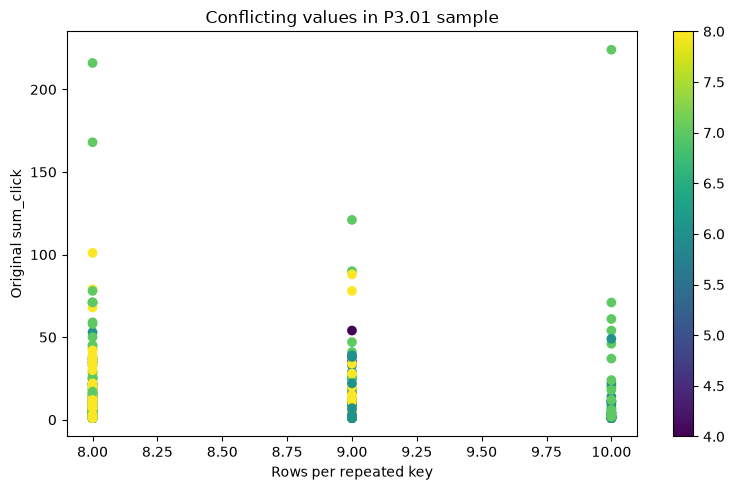

Unknown registration dates: 45


,code_module,code_presentation,id_student,date_registration,date_unregistration,module_presentation_length,final_result,gender,age_band,highest_education,imd_band,disability,activity_rows,parseable_click_rows,recorded_clicks,pre_course_rows,in_course_rows,post_course_rows,unclassified_temporal_rows,activity_context
0,BBB,2013B,630346,?,?,240,Fail,F,0-35,A Level or Equivalent,60-70%,Y,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
1,BBB,2013J,342678,?,-33,268,Withdrawn,F,0-35,A Level or Equivalent,50-60%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
2,BBB,2013J,57369,?,-1,268,Withdrawn,M,35-55,Lower Than A Level,40-50%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
3,BBB,2014B,2409808,?,-109,234,Withdrawn,F,35-55,Lower Than A Level,60-70%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
4,BBB,2014B,2439442,?,-149,234,Withdrawn,F,0-35,Lower Than A Level,20-30%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
5,BBB,2014B,582496,?,-126,234,Withdrawn,F,0-35,Lower Than A Level,0-10%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
6,BBB,2014B,607646,?,-38,234,Withdrawn,F,0-35,Lower Than A Level,10-20,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
7,BBB,2014B,614270,?,-142,234,Withdrawn,F,0-35,A Level or Equivalent,50-60%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
8,BBB,2014J,694001,?,-36,262,Withdrawn,F,0-35,A Level or Equivalent,20-30%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW
9,CCC,2014B,1600062,?,-152,241,Withdrawn,M,35-55,A Level or Equivalent,70-80%,N,0,0,0,0,0,0,0,NO_RECORDED_VLE_ROW


,final_result,records
0,Fail,5
1,Pass,1
2,Withdrawn,39


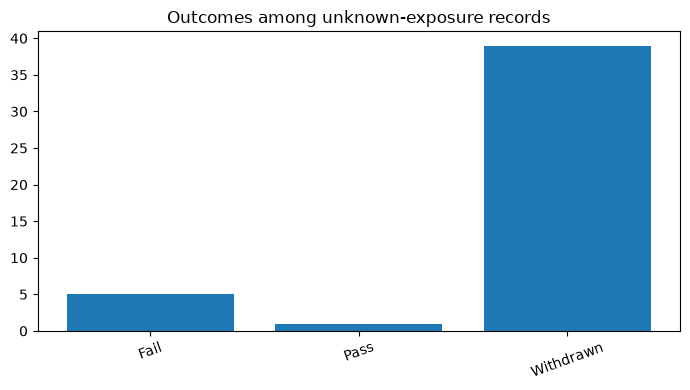

,activity_state,student_presentations,cohort_pct
0,HAS_IN_COURSE_ACTIVITY,28500,87.442089
1,NO_RECORDED_VLE_ROW,3365,10.324303
2,PRE_COURSE_ONLY,728,2.233608


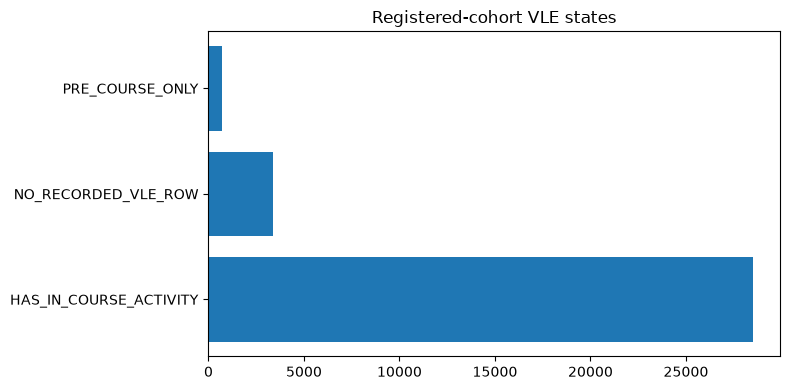

P3.05 direct rows: 1927 grouped -1 rows: 1927 — row-level and grouped counts agree; sentinel meaning remains unresolved.
P3.06 categorical inventory


,source_field,source_value,occurrences
0,assessments.assessment_type,TMA,106
1,assessments.assessment_type,CMA,76
2,assessments.assessment_type,Exam,24
3,student_assessment.is_banked,0,172003
4,student_assessment.is_banked,1,1909
...,...,...,...
60,vle.activity_type,dualpane,20
61,vle.activity_type,repeatactivity,5
62,vle.activity_type,htmlactivity,4
63,vle.activity_type,sharedsubpage,3


P3.06 numeric domains


,source_field,source_rows,blank_or_null_rows,question_mark_rows,unparseable_rows,minimum_value,maximum_value,distinct_numeric_values
0,assessments.date,206,0,11,0,12,261,74
1,assessments.weight,206,0,0,0,0,100,24
2,courses.module_presentation_length,22,0,0,0,234,269,7
3,student_assessment.date_submitted,173912,0,0,0,-11,608,312
4,student_assessment.score,173912,0,173,0,0,100,101
5,student_info.num_of_prev_attempts,32593,0,0,0,0,6,7
6,student_info.studied_credits,32593,0,0,0,30,655,61
7,student_registration.date_registration,32593,0,45,0,-322,167,332
8,student_registration.date_unregistration,32593,0,22521,0,-365,444,416
9,student_vle.date,10655280,0,0,0,-25,269,295


In [ ]:
# Saved visual-review outputs are retained snapshots; P3.02/P3.05 currentness is determined only by the hash-aware manifest loader.
# Visual review of retained P3 exports only.
import matplotlib.pyplot as plt
from IPython.display import display
if p301_results is not None:
    s=p301_results[1]; g=s.drop_duplicates(["code_module","code_presentation","id_student","id_site","date"])
    display(g[["code_module","code_presentation","id_student","id_site","date","group_rows","distinct_nonnull_click_values","minimum_numeric_clicks","maximum_numeric_clicks"]])
    fig,ax=plt.subplots(figsize=(8,5)); sc=ax.scatter(s["group_rows"],s["original_sum_click"],c=s["distinct_nonnull_click_values"])
    ax.set_xlabel("Rows per repeated key"); ax.set_ylabel("Original sum_click"); ax.set_title("Conflicting values in P3.01 sample"); fig.colorbar(sc,ax=ax); fig.tight_layout(); plt.show()
if p303_results is not None:
    u=p303_results[1]; print("Unknown registration dates:",len(u)); display(u)
    if "final_result" in u:
        q=u.groupby("final_result",dropna=False).size().rename("records").reset_index(); display(q)
        fig,ax=plt.subplots(figsize=(7,4)); ax.bar(q["final_result"].astype(str),q["records"]); ax.set_title("Outcomes among unknown-exposure records"); ax.tick_params(axis="x",rotation=20); fig.tight_layout(); plt.show()
if p304_cohort is not None:
    q=p304_cohort.groupby("activity_state",dropna=False).size().rename("student_presentations").reset_index(); q["cohort_pct"]=q.student_presentations/len(p304_cohort)*100; display(q)
    fig,ax=plt.subplots(figsize=(8,4)); ax.barh(q.activity_state,q.student_presentations); ax.set_title("Registered-cohort VLE states"); fig.tight_layout(); plt.show()
if p305_results is not None:
    direct=len(p305_results[1])
    grouped=int(p305_results[2].loc[p305_results[2].submission_day_state=="DAY_MINUS_ONE_UNRESOLVED","submission_records"].sum())
    print("P3.05 row-level -1 rows:",direct,"grouped -1 rows:",grouped,
          "| numerical reconciliation:", "PASS" if direct==grouped else "REVIEW")
    if 5 in p305_results:
        print("P3.05 direct source-grain reconciliation:")
        display(p305_results[5])
    else:
        print("P3.05 fifth source-grain result set is absent; do not recode -1.")
if p306_results is not None:
    print("P3.06 categorical inventory"); display(p306_results[1]); print("P3.06 numeric domains"); display(p306_results[2])

## 08 — Evidence review and decision register

| Area | Evidence | Decision | State |
|---|---|---|---|
| Source snapshot / join grain | P3.00 and P3.07 | Accept tested source inventory and composite join keys within tested scope | Accepted |
| Repeated VLE rows | P3.01 and AN8.30 | R0 source-faithful; R1/R2 sensitivity only | No dedup rule |
| Relative days | Accepted P3.02 output and OULAD descriptor | Preserve negative offsets; distinguish day 0 and day L; no calendar conversion without an anchor | Historical baseline accepted |
| Registration | P3.03 | Keep 45 exposures unknown | Accepted |
| Activity states | P3.04 | Keep in-course, no-row, pre-course-only separate | Accepted |
| Assessment transfer/timing | P3.05 retained evidence + P3.09 | Exclude banked transfers from current submission/timeliness measures; review non-banked negative dates case by case | P3.09 execution pending |
| Assessment opportunity | P3.09 | Candidate denominator by known due date; separate withdrawal-on-deadline, unknown registration, and withdrawn outcome with unknown unregistration | Provisional |
| Domains | P3.06 | No blanket normalization or imputation | Inventory only |
| KPIs | P3.09 candidate contracts | Eligible count, current submission coverage, on-time rate, valid-score pass rate, banked-result share | Draft only |

No deletion, deduplication, imputation, outlier removal, index, or persistent derived object is approved.

In [ ]:
# Saved review outputs below are historical snapshots. Re-load through the hash-aware gate before treating P3.02/P3.05 as current.
diagnostic_results = {
    "P3.01": p301_results,
    "P3.02": p302_results,
    "P3.03": p303_results,
    "P3.05": p305_results,
    "P3.06": p306_results,
}

for query_id, result_sets in diagnostic_results.items():
    historical = False
    if result_sets is None and query_id in {"P3.02", "P3.05"}:
        try:
            historical_manifest, result_sets = load_query_results(query_id, allow_stale=True)
            historical = bool(historical_manifest.get("_sql_is_stale"))
            print(f"\n{query_id}: {'HISTORICAL / STALE' if historical else 'CURRENT'}")
            print("Execution UTC:", historical_manifest.get("executed_at_utc"))
        except (FileNotFoundError, IndexError):
            result_sets = None
    if result_sets is None:
        print(f"\n{query_id}: no retained result loaded.")
        continue
    print(f"\n{query_id} result review" + (" — HISTORICAL / STALE" if historical else ""))
    for result_number, frame in result_sets.items():
        print(f"Result set {result_number}: {len(frame):,} rows")
        if query_id == "P3.05" and result_number == 1 and len(frame) > 100:
            display(frame.head(100))
            print("Preview limited to 100 rows; full CSV remains locally retained.")
        else:
            display(frame)
    if query_id == "P3.05" and historical and len(result_sets) < 5:
        print("The fifth source-grain reconciliation is not present in this historical export.")


P3.01 result review
Result set 1: 430 rows


,code_module,code_presentation,id_student,id_site,date,original_sum_click,group_rows,distinct_nonnull_click_values,null_click_rows,blank_click_rows,question_mark_click_rows,minimum_numeric_clicks,maximum_numeric_clicks
0,EEE,2013J,2569834,551072,156,1,10,7,0,0,0,1,71
1,EEE,2013J,2569834,551072,156,2,10,7,0,0,0,1,71
2,EEE,2013J,2569834,551072,156,2,10,7,0,0,0,1,71
3,EEE,2013J,2569834,551072,156,2,10,7,0,0,0,1,71
4,EEE,2013J,2569834,551072,156,2,10,7,0,0,0,1,71
...,...,...,...,...,...,...,...,...,...,...,...,...,...
425,FFF,2014J,676190,882554,144,12,8,8,0,0,0,1,39
426,FFF,2014J,676190,882554,144,2,8,8,0,0,0,1,39
427,FFF,2014J,676190,882554,144,3,8,8,0,0,0,1,39
428,FFF,2014J,676190,882554,144,39,8,8,0,0,0,1,39



P3.02 result review
Result set 1: 5 rows


,source_field,source_rows,blank_or_null_rows,question_mark_tokens,non_integer_tokens,negative_rows,day_zero_rows,positive_rows,minimum_relative_day,maximum_relative_day
0,assessments.date,206,0,11,0,0,0,195,12,261
1,student_assessment.date_submitted,173912,0,0,0,2057,61,171794,-11,608
2,student_registration.date_registration,32593,0,45,0,32312,2,234,-322,167
3,student_registration.date_unregistration,32593,0,22521,0,2678,419,6975,-365,444
4,student_vle.date,10655280,0,0,0,688988,76643,9889649,-25,269


Result set 2: 200 rows


,code_module,code_presentation,id_student,id_site,source_relative_day,module_presentation_length,observed_temporal_state,sum_click
0,AAA,2013J,100893,546662,-2,268,PRE_START,6
1,AAA,2013J,100893,546879,-9,268,PRE_START,3
2,AAA,2013J,100893,546652,-9,268,PRE_START,2
3,AAA,2013J,100893,546614,-9,268,PRE_START,4
4,AAA,2013J,100893,546681,-2,268,PRE_START,1
...,...,...,...,...,...,...,...,...
195,AAA,2013J,104476,546652,-10,268,PRE_START,4
196,AAA,2013J,104476,546876,-10,268,PRE_START,7
197,AAA,2013J,104476,546903,-10,268,PRE_START,1
198,AAA,2013J,104476,546684,-10,268,PRE_START,11


... (12 outputs left out)


P3.06 result review
Result set 1: 65 rows


,source_field,source_value,occurrences
0,assessments.assessment_type,TMA,106
1,assessments.assessment_type,CMA,76
2,assessments.assessment_type,Exam,24
3,student_assessment.is_banked,0,172003
4,student_assessment.is_banked,1,1909
...,...,...,...
60,vle.activity_type,dualpane,20
61,vle.activity_type,repeatactivity,5
62,vle.activity_type,htmlactivity,4
63,vle.activity_type,sharedsubpage,3


Result set 2: 13 rows


,source_field,source_rows,blank_or_null_rows,question_mark_rows,unparseable_rows,minimum_value,maximum_value,distinct_numeric_values
0,assessments.date,206,0,11,0,12,261,74
1,assessments.weight,206,0,0,0,0,100,24
2,courses.module_presentation_length,22,0,0,0,234,269,7
3,student_assessment.date_submitted,173912,0,0,0,-11,608,312
4,student_assessment.score,173912,0,173,0,0,100,101
5,student_info.num_of_prev_attempts,32593,0,0,0,0,6,7
6,student_info.studied_credits,32593,0,0,0,30,655,61
7,student_registration.date_registration,32593,0,45,0,-322,167,332
8,student_registration.date_unregistration,32593,0,22521,0,-365,444,416
9,student_vle.date,10655280,0,0,0,-25,269,295


## 07B — P3.04 cohort reconciliation

P3.04 returns one row per registered student-presentation. After its execution cell, review the full cohort, validate the composite grain, and reconcile the historical 3,365 no-row and 4,093 no-in-course counts. Derive the 728 difference from actual row-level states; do not presume it is pre-course-only.

### P3.04 review — complete registered cohort

The query execution gate is in Section 07. Review the retained full-cohort output below. The historical 728 difference is a reconciliation target, not a presumed pre-course-only cohort.

In [24]:
p304_manifest = None
p304_results = None
p304_cohort = None

if find_query_manifests("P3.04"):
    p304_manifest, p304_results = load_query_results("P3.04")
    if len(p304_results) != 1:
        raise ValueError("P3.04 must return exactly one complete cohort result set.")
    p304_cohort = p304_results[1]

    required_columns = {
        "code_module", "code_presentation", "id_student",
        "all_activity_rows", "pre_rows", "in_rows", "post_rows",
        "unclassified_rows", "activity_state",
    }
    missing = required_columns - set(p304_cohort.columns)
    if missing:
        raise ValueError(f"P3.04 missing required columns: {sorted(missing)}")

    cohort_key = ["code_module", "code_presentation", "id_student"]
    print("P3.04 row count:", len(p304_cohort))
    print("Distinct registered keys:", p304_cohort[cohort_key].drop_duplicates().shape[0])
    print("Duplicate output keys:", p304_cohort.duplicated(cohort_key).sum())

    state_summary = (
        p304_cohort.groupby("activity_state", dropna=False)
        .size().rename("student_presentations").reset_index()
        .sort_values("activity_state")
    )
    display(state_summary)

    historical_comparison = pd.DataFrame([
        {
            "measure": "No recorded VLE row",
            "historical_AN8": 3365,
            "P3.04_source_ref": int((p304_cohort["all_activity_rows"] == 0).sum()),
        },
        {
            "measure": "No in-course VLE row",
            "historical_AN8": 4093,
            "P3.04_source_ref": int((p304_cohort["in_rows"] == 0).sum()),
        },
        {
            "measure": "Difference",
            "historical_AN8": 728,
            "P3.04_source_ref": int((p304_cohort["in_rows"] == 0).sum())
                - int((p304_cohort["all_activity_rows"] == 0).sum()),
        },
    ])
    display(historical_comparison)

    print("No-in-course records by exact activity state:")
    display(
        p304_cohort.loc[p304_cohort["in_rows"] == 0]
        .groupby("activity_state", dropna=False)
        .size().rename("student_presentations").reset_index()
    )

    print("Presentation/outcome/state breakdown:")
    display(
        p304_cohort.groupby(
            ["code_module", "code_presentation", "final_result", "activity_state"],
            dropna=False,
        ).size().rename("student_presentations").reset_index()
    )
else:
    print("P3.04 NOT AVAILABLE — the 728-record difference remains unverified.")

P3.04 row count: 32593
Distinct registered keys: 32593
Duplicate output keys: 0


,activity_state,student_presentations
0,HAS_IN_COURSE_ACTIVITY,28500
1,NO_RECORDED_VLE_ROW,3365
2,PRE_COURSE_ONLY,728


,measure,historical_AN8,P3.04_source_ref
0,No recorded VLE row,3365,3365
1,No in-course VLE row,4093,4093
2,Difference,728,728


No-in-course records by exact activity state:


,activity_state,student_presentations
0,NO_RECORDED_VLE_ROW,3365
1,PRE_COURSE_ONLY,728


Presentation/outcome/state breakdown:


,code_module,code_presentation,final_result,activity_state,student_presentations
0,AAA,2013J,Distinction,HAS_IN_COURSE_ACTIVITY,20
1,AAA,2013J,Fail,HAS_IN_COURSE_ACTIVITY,45
2,AAA,2013J,Pass,HAS_IN_COURSE_ACTIVITY,258
3,AAA,2013J,Withdrawn,HAS_IN_COURSE_ACTIVITY,53
4,AAA,2013J,Withdrawn,NO_RECORDED_VLE_ROW,5
...,...,...,...,...,...
168,GGG,2014J,Fail,PRE_COURSE_ONLY,3
169,GGG,2014J,Pass,HAS_IN_COURSE_ACTIVITY,317
170,GGG,2014J,Withdrawn,HAS_IN_COURSE_ACTIVITY,87
171,GGG,2014J,Withdrawn,NO_RECORDED_VLE_ROW,33


### 07A.1 — P3.02 relative-day interpretation

OULAD date fields are offsets from the start of a module-presentation (day 0). The dataset descriptor also explains that VLE materials may be available before the official start. Negative `student_vle.date` values are therefore pre-start observations, not automatic errors. Source: [OULAD data descriptor](https://doi.org/10.1038/sdata.2017.171).

| Field | Rows | Negative | Day 0 | Positive | `?` |
|---|---:|---:|---:|---:|---:|
| `student_vle.date` | 10,655,280 | 688,988 | 76,643 | 9,889,649 | 0 |
| `date_registration` | 32,593 | 32,312 | 2 | 234 | 45 |
| `date_unregistration` | 32,593 | 2,678 | 419 | 6,975 | 22,521 |
| `assessments.date` | 206 | 0 | 0 | 195 | 11 |
| `date_submitted` | 173,912 | 2,057 | 61 | 171,794 | 0 |

For VLE rows, pre-start is 6.47%, day zero 0.72%, and positive offsets 92.81%. These are activity-row shares, not student or click shares. The retained execution shows max VLE offset equals presentation length in all 22 presentations. Keep the established AN5/AN6 interval `0 <= day <= module_presentation_length` for comparability, but flag day L separately. No calendar conversion without a verified presentation start-date anchor.

**Evidence state:** saved output predates the revised P3.02 SQL and is historical until re-executed.

In [ ]:
# P3.02 retained output review and visualizations.
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_rows", None)
if p302_results is not None:
    pm, pr = p302_manifest, p302_results
else:
    pm, pr = load_query_results("P3.02", allow_stale=True)
stale = bool(pm.get("_sql_is_stale"))
print("P3.02:", "HISTORICAL / STALE" if stale else "CURRENT")
print("Execution UTC:", pm.get("executed_at_utc"))
t=pr[1].copy()
t["negative_pct"]=t["negative_rows"]/t["source_rows"]*100
t["day_zero_pct"]=t["day_zero_rows"]/t["source_rows"]*100
t["positive_pct"]=t["positive_rows"]/t["source_rows"]*100
display(t)
fig,ax=plt.subplots(figsize=(11,5)); left=pd.Series(0.0,index=t.index)
for col,label in [("negative_rows","Negative"),("day_zero_rows","Day 0"),("positive_rows","Positive"),("question_mark_tokens","?"),("blank_or_null_rows","Blank/NULL")]:
    pct=t[col]/t["source_rows"]*100
    if pct.sum(): ax.barh(t["source_field"],pct,left=left,label=label); left+=pct
ax.set_xlabel("Share of source rows (%)"); ax.set_title("Relative-day states by source field"); ax.legend(); ax.invert_yaxis(); fig.tight_layout(); plt.show()
p=pr[3].copy(); p["max_vle_equals_length"]=p["max_vle_relative_day"]==p["module_presentation_length"]
print("Presentations where max VLE day equals length:",int(p["max_vle_equals_length"].sum()),"/",len(p)); display(p)
fig,ax=plt.subplots(figsize=(7,6)); ax.scatter(p["module_presentation_length"],p["max_vle_relative_day"])
lo=min(p["module_presentation_length"].min(),p["max_vle_relative_day"].min()); hi=max(p["module_presentation_length"].max(),p["max_vle_relative_day"].max())
ax.plot([lo,hi],[lo,hi],linestyle="--",label="Equality boundary"); ax.set_xlabel("Presentation length"); ax.set_ylabel("Maximum VLE relative day"); ax.set_title("Observed VLE maximum vs presentation length"); ax.legend(); fig.tight_layout(); plt.show()
display(pr[2])

## 07 — Evidence review and decision register

No transformation is implemented in this section. Record only decisions supported by reviewed P3 outputs and source documentation. Keep unresolved items explicitly open.

## 09 — Controlled Python processing design

No transformation is executed yet. Proposed derived fields are `relative_day_state` (PRE_START, START_DAY, WITHIN_INTERVAL, PRESENTATION_END_BOUNDARY, AFTER_LENGTH_BOUNDARY, UNKNOWN), `submission_day_state` (with -1 unresolved), `registration_exposure_state` (KNOWN/UNKNOWN), `activity_state` (in-course/no-row/pre-course-only), `score_state` (missing/zero/nonzero), and `student_vle_scenario` (R0/R1/R2). Preserve source fields; process studentVle in chunks; record rule IDs, affected rows/keys, before/after counts, click totals, alternatives and approval. No persistent objects without separate authorization.

## 10 — Reporting contract gate

Candidate descriptive indicators (not production KPIs):

| Indicator | Numerator / denominator | Value | Limit |
|---|---|---:|---|
| In-course recorded activity coverage | 28,500 / 32,593 | 87.44% | Platform activity only |
| No recorded VLE row | 3,365 / 32,593 | 10.32% | Not proof of no study |
| Pre-course-only activity | 728 / 32,593 | 2.23% | Separate from no-row |
| Combined no in-course activity | 4,093 / 32,593 | 12.56% | Show components |
| Pre-start activity-row share | 688,988 / 10,655,280 | 6.47% | Not learner/click share |

Use the established 0..module_presentation_length window for AN5/AN6 comparability, but flag day L. Keep R0/R1/R2 visible. No composite engagement score or adjusted click total is approved. Every metric contract needs grain, population, numerator, denominator, time basis, NULL/zero treatment, scenario, join path, lineage, validation and permitted interpretation. AN9 remains blocked pending P3.02/P3.05 reconciliation and approved curated outputs.

## 11 — P3.09 assessment opportunity and temporal semantics

P3.05 retained evidence shows 1,927 `date_submitted = -1` rows: 1,909 are banked and 18 are not. The banked majority is consistent with transferred results, but the 18 non-banked records and 130 other negative-day records below -1 require case-level review. Official OULAD documentation defines `is_banked=1` as a result transferred from a previous presentation; banked rows therefore do not represent current-presentation submissions.

The retained P3.05 output also identifies 11 Exam items without due dates. Three have linked result rows (CCC 2014B: 747; CCC 2014J: 1,168; DDD 2014J: 950); eight have none. Unknown due dates block deadline/timeliness calculations, not necessarily score-outcome reporting.

**Business interpretation:** distinguish (1) a learner eligible to submit, (2) a current-presentation submission, (3) a result transferred from an earlier presentation, (4) a late/on-time result, and (5) an unknown/unclassifiable case. A result row is not automatically a current submission. A score of zero is an observed score, not a missing result.

P3.09 returns five result sets: assessment catalogue/weights; per-assessment banked, score, date, and deadline states; every -1 record with registration/outcome context; every negative submission day; and candidate eligible denominators reconciled to current non-banked non-negative dated results. The candidate population is registered on/before a known due day and not withdrawn before it. Withdrawals on the due day, Withdrawn outcomes with unknown unregistration day, and unknown registration dates remain separate. Current-result coverage excludes negative dates. Unknown-due-date assessments are excluded from deadline-based denominators and disclosed separately.

**Provisional stakeholder measures after P3.09 validation:** eligible learner count; recorded current-submission coverage; on-time submission rate; pass rate among valid current scores (score >=40); and banked-result share as a separate transfer-history measure. These definitions are drafts, not approved KPIs. The final denominator, exam treatment, and unresolved negative-date states must be validated before derived outputs are built.

Source: Kuzilek, Hlosta & Zdrahal (2017), OULAD data descriptor, https://doi.org/10.1038/sdata.2017.171.

In [ ]:
# P3.09 — assessment opportunity, transfer, and temporal semantics
AUTHORIZE_P309_EXECUTION = False
p309_manifest, p309_results = (None, None)
if not P300_GATE_PASSED or p307_manifest is None:
    print("P3.09 BLOCKED — P3.00/P3.07 structural gates are unavailable.")
else:
    p309_manifest, p309_results = load_or_execute_part3_query("P3.09", AUTHORIZE_P309_EXECUTION)
    if p309_results is not None:
        print("P3.09 result sets:", len(p309_results))
        for result_number, frame in p309_results.items():
            print(f"Result set {result_number}: {len(frame):,} rows")
            display(frame.head(100))
            if len(frame) > 100:
                print("Preview limited to 100 rows; full CSV retained with manifest.")